[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/USERNAME_GITHUB/NAMA_REPO/blob/main/NAMA_FILE.ipynb)

In [ ]:
!pip install pyspark duckdb matplotlib pandas -q

import duckdb
import pandas as pd

print("PREPARASI DATASET TPC-H (SF=0.01)")
con = duckdb.connect()
con.execute("CALL dbgen(sf = 0.01);")


df_customer = con.execute("SELECT c_custkey, c_name, c_address, c_acctbal FROM customer").df()
display(df_customer.head(10))

PREPARASI DATASET TPC-H (SF=0.01)


,c_custkey,c_name,c_address,c_acctbal
0,1,Customer#000000001,j5JsirBM9PsCy0O1m,711.56
1,2,Customer#000000002,487LW1dovn6Q4dMVymKwwLE9OKf3QG,121.65
2,3,Customer#000000003,fkRGN8nY4pkE,7498.12
3,4,Customer#000000004,4u58h fqkyE,2866.83
4,5,Customer#000000005,hwBtxkoBF qSW4KrIk5U 2B1AU7H,794.47
5,6,Customer#000000006,"g1s,pzDenUEBW3O,2 pxu0f9n2g64rJrt5E",7638.57
6,7,Customer#000000007,8OkMVLQ1dK6Mbu6WG9 w4pLGQ n7MQ,9561.95
7,8,Customer#000000008,"j,pZ,Qp,qtFEo0r0c 92qobZtlhSuOqbE4JGV",6819.74
8,9,Customer#000000009,vgIql8H6zoyuLMFNdAMLyE7 H9,8324.07
9,10,Customer#000000010,"Vf mQ6Ug9Ucf5OKGYq fsaX AtfsO7,rwY",2753.54


In [ ]:
import time
import json
import sqlite3
from pyspark.sql import SparkSession

conn_sq = sqlite3.connect(":memory:")
df_customer.to_sql("customer", conn_sq, index=False, if_exists="replace")

nosql_records = []
for _, row in df_customer.iterrows():
    nosql_records.append({
        "key": f"customer:{int(row['c_custkey'])}",
        "value": json.dumps({
            "c_custkey": int(row['c_custkey']),
            "c_name": row['c_name'],
            "c_address": row['c_address'],
            "c_acctbal": float(row['c_acctbal'])
        })
    })

spark = SparkSession.builder \
    .appName("PolyFuseQL-Colab-Replication") \
    .master("local[*]") \
    .getOrCreate()

print("EKSPERIMEN EVALUASI PERFORMA PYSPARK")

start_rdbms = time.time()
df_spark_rdbms = spark.createDataFrame(df_customer)
df_spark_rdbms.createOrReplaceTempView("cust_rdbms")
res_rdbms = spark.sql("SELECT COUNT(*) as total, AVG(c_acctbal) as avg_bal FROM cust_rdbms").collect()
time_rdbms = time.time() - start_rdbms

# UJI 2: NoSQL
start_nosql = time.time()
parsed_nosql = [json.loads(item["value"]) for item in nosql_records]
df_spark_nosql = spark.createDataFrame(parsed_nosql)
df_spark_nosql.createOrReplaceTempView("cust_nosql")
res_nosql = spark.sql("SELECT COUNT(*) as total, AVG(c_acctbal) as avg_bal FROM cust_nosql").collect()
time_nosql = time.time() - start_nosql

print(f"Execution Time RDBMS (SQL)       : {time_rdbms:.4f} detik")
print(f"Execution Time NoSQL (Key-Value) : {time_nosql:.4f} detik\n")

df_metrics = pd.DataFrame({
    'Architecture': ['RDBMS (PostgreSQL/SQL)', 'NoSQL (Key-Value/Redis)'],
    'Execution_Time_Seconds': [round(time_rdbms, 4), round(time_nosql, 4)],
    'Status': ['Completed', 'Completed']
})

df_metrics.to_csv("execution_time.csv", index=False)

EKSPERIMEN EVALUASI PERFORMA PYSPARK
Execution Time RDBMS (SQL)       : 0.8384 detik
Execution Time NoSQL (Key-Value) : 0.7112 detik



MEMBUAT GRAFIK VISUALISASI HASIL
Grafik berhasil disimpan sebagai 'hasil_eksperimen.png'!


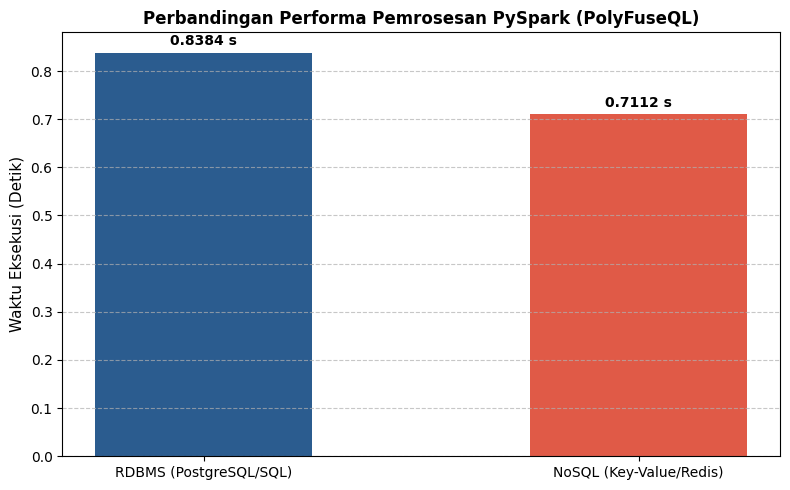

In [12]:
import matplotlib.pyplot as plt

print("MEMBUAT GRAFIK VISUALISASI HASIL")
categories = df_metrics['Architecture']
execution_times = df_metrics['Execution_Time_Seconds']

plt.figure(figsize=(8, 5))
bars = plt.bar(categories, execution_times, color=['#2b5c8f', '#e05a47'], width=0.5)
plt.ylabel('Waktu Eksekusi (Detik)', fontsize=11)
plt.title('Perbandingan Performa Pemrosesan PySpark (PolyFuseQL)', fontsize=12, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + (max(execution_times)*0.01), f'{yval:.4f} s', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("hasil_eksperimen.png", dpi=300)

print("Grafik berhasil disimpan sebagai 'hasil_eksperimen.png'!")